# Register distibution

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# ==========================================
# PLOTTING AND SAVING SETTINGS
# ==========================================

FIG_SIZE = (12, 7)
FIG_DPI = 300

OUTPUT_DIR = "plots"

plt.rcParams.update({
    "figure.figsize": FIG_SIZE,
    "figure.dpi": FIG_DPI,
    "savefig.dpi": FIG_DPI,
    "font.family": "Arial",
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "legend.title_fontsize": 11,
})

In [3]:
def save_plot(fig, filename, output_dir=OUTPUT_DIR):

    os.makedirs(output_dir, exist_ok=True)

    # Save PNG
    png_path = os.path.join(output_dir, f"{filename}.png")

    fig.savefig(
        png_path,
        dpi=FIG_DPI,
        bbox_inches="tight",
        facecolor="white",
        format="png"
    )

    # Save PDF
    pdf_path = os.path.join(output_dir, f"{filename}.pdf")

    fig.savefig(
        pdf_path,
        bbox_inches="tight",
        facecolor="white",
        format="pdf"
    )

    print(f"PNG saved: {png_path}")
    print(f"PDF saved: {pdf_path}")

In [4]:

df = pd.read_csv(
    r"C:\Users\alrazz\Documents\GitHub\persian_registers\Register\csv_output\without_NA\Combined_single_no_NA.csv"
)

print("Dataset loaded successfully!")
print(f"Number of rows: {len(df)}")
print(f"Number of unique documents: {df['id'].nunique()}")

display(df.head())

Dataset loaded successfully!
Number of rows: 6300
Number of unique documents: 4205


,u,id,ts,text,Turku_NLP,Turku_NLP_sub,Tags,web-register,Turku_NLP_split,Turku_NLP_sub_split,Turku_NLP_sub_split_modified,source
0,http://roshangari.info/?p=35434,110ae9e775485f536c4f1cdea087cbd7,2020-01-25T19:50:48Z,e.shafagh@yahoo.com\r\n“تاریخ گواهی خواهد داد ...,IP ; ID,ed ; -,OTHLI,"{""MT"": 0.074, ""LY"": 0.084, ""SP"": 0.105, ""ID"": ...",IP,ed,ed,Combined_single
1,http://roshangari.info/?p=35434,110ae9e775485f536c4f1cdea087cbd7,2020-01-25T19:50:48Z,e.shafagh@yahoo.com\r\n“تاریخ گواهی خواهد داد ...,IP ; ID,ed ; -,OTHLI,"{""MT"": 0.074, ""LY"": 0.084, ""SP"": 0.105, ""ID"": ...",ID,-,ID,Combined_single
2,https://www.tinn.ir/%D8%A8%D8%AE%D8%B4-%D9%88%...,32962503dcdb08ee1bc4d2e9d5240bc7,2020-01-19T18:40:03Z,در کشورهای پیشرفته که حملونقل بر اساس پژوهشهای...,IP,ed,NaN,"{""MT"": 0.089, ""LY"": 0.085, ""SP"": 0.125, ""ID"": ...",IP,ed,ed,Combined_single
3,http://p313.ir/post-124289.html,0e6562306fcb8db55e019445407cb487,2016-10-26T00:51:16Z,مهدی محمدی طی یادداشتی در روزنامه وطن امروز نو...,IP,ed,NaN,"{""MT"": 0.093, ""LY"": 0.063, ""SP"": 0.11900000000...",IP,ed,ed,Combined_single
4,http://shakhesnews.com/%db%b6-%d8%af%d8%a7%d9%...,588d3acafdc57f5122849f3163c1d357,2016-10-27T18:45:54Z,شاخص : اگر مسیر مذاکرات در همین جهت ادامه یابد...,IP,ed,OTHLI,"{""MT"": 0.092, ""LY"": 0.07100000000000001, ""SP"":...",IP,ed,ed,Combined_single


In [5]:
labels_structure = {
    "MT": ["-"],
    "LY": ["-"],
    "SP": ["it", "os"],
    "ID": ["-"],
    "NA": ["ne", "sr", "nb", "on"],
    "HI": ["re", "oh"],
    "IN": ["en", "ra", "dtp", "fi", "lt", "oi"],
    "OP": ["rv", "ob", "rs", "av", "oo"],
    "IP": ["ds", "ed", "oe"],
}

In [6]:

def process_hierarchy(df, parent_col="Turku_NLP", child_col="Turku_NLP_sub"):

    records = []

    for _, row in df.iterrows():

        parents = (
            str(row[parent_col]).split(";")
            if pd.notna(row[parent_col])
            else []
        )

        children = (
            str(row[child_col]).split(";")
            if pd.notna(row[child_col])
            else []
        )

        parents = [x.strip() for x in parents if x.strip()]
        children = [x.strip() for x in children if x.strip()]

        # Check parent-child alignment
        if len(parents) != len(children):

            records.append({
                "id": row["id"],
                "parent": None,
                "child": None,
                "valid": False,
                "problem": (
                    f"Number of parents ({len(parents)}) != "
                    f"number of children ({len(children)})"
                )
            })

            continue

        for parent, child in zip(parents, children):

            valid = (
                parent in labels_structure
                and child in labels_structure[parent]
            )

            if parent not in labels_structure:

                problem = f"Unknown parent label: {parent}"

            elif child not in labels_structure[parent]:

                possible_parents = [
                    p for p, children_list in labels_structure.items()
                    if child in children_list
                ]

                if possible_parents:
                    problem = (
                        f"{child} is defined under {possible_parents}, "
                        f"but was assigned to {parent}"
                    )
                else:
                    problem = f"Unknown sublabel: {child}"

            else:
                problem = None

            records.append({
                "id": row["id"],
                "parent": parent,
                "child": child,
                "valid": valid,
                "problem": problem
            })

    return pd.DataFrame(records)


# Process dataset
processed_hierarchy = process_hierarchy(df)

# Keep valid combinations
valid_hierarchy = processed_hierarchy[
    processed_hierarchy["valid"]
].copy()

In [8]:

total_documents = df["id"].nunique()

print("=" * 60)
print(f"TOTAL NUMBER OF UNIQUE DOCUMENTS: {total_documents}")
print("=" * 60)

TOTAL NUMBER OF UNIQUE DOCUMENTS: 4205


In [9]:

parent_counts = (
    valid_hierarchy
    .groupby("parent")["id"]
    .nunique()
    .reindex(labels_structure.keys(), fill_value=0)
    .reset_index()
)

parent_counts.columns = [
    "Parent label",
    "Number of documents"
]

print("DOCUMENT COUNTS PER PARENT LABEL")

display(parent_counts)

print(
    "Sum of parent label counts:",
    parent_counts["Number of documents"].sum()
)

DOCUMENT COUNTS PER PARENT LABEL


,Parent label,Number of documents
0,MT,208
1,LY,315
2,SP,405
3,ID,390
4,NA,625
5,HI,411
6,IN,1418
7,OP,922
8,IP,735


Sum of parent label counts: 5429


In [10]:

child_counts = (
    valid_hierarchy
    .groupby("child")["id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index()
)

child_counts.columns = [
    "Sub-label",
    "Number of documents"
]

print("DOCUMENT COUNTS PER SUB-LABEL")

display(child_counts)

DOCUMENT COUNTS PER SUB-LABEL


,Sub-label,Number of documents
0,-,882
1,dtp,477
2,oi,354
3,ds,333
4,ne,286
5,av,269
6,lt,264
7,ob,240
8,oe,236
9,oh,233


In [11]:

hierarchy_counts = (
    valid_hierarchy
    .groupby(["parent", "child"])["id"]
    .nunique()
    .reset_index(name="Number of documents")
)

hierarchy_counts = hierarchy_counts.sort_values(
    ["parent", "child"]
)

print("DOCUMENT COUNTS PER PARENT-SUB-LABEL COMBINATION")

display(hierarchy_counts)

DOCUMENT COUNTS PER PARENT-SUB-LABEL COMBINATION


,parent,child,Number of documents
0,HI,oh,233
1,HI,re,178
2,ID,-,390
3,IN,dtp,477
4,IN,en,151
5,IN,fi,179
6,IN,lt,264
7,IN,oi,354
8,IN,ra,172
9,IP,ds,333


In [12]:

# Keep only the first sub-label for each document-parent combination
exclusive_hierarchy = (
    valid_hierarchy
    .drop_duplicates(
        subset=["id", "parent"],
        keep="first"
    )
    .copy()
)

# Remove "-" parent
exclusive_hierarchy = exclusive_hierarchy[
    exclusive_hierarchy["parent"] != "-"
].copy()


# Create separate plotting labels for MT, LY and ID
exclusive_hierarchy["plot_child"] = exclusive_hierarchy["child"]

exclusive_hierarchy.loc[
    exclusive_hierarchy["parent"].isin(["MT", "LY", "ID"]),
    "plot_child"
] = exclusive_hierarchy["parent"] + "_no_child"


# Count documents per parent-child combination
counts = (
    exclusive_hierarchy
    .groupby(["parent", "plot_child"])["id"]
    .nunique()
    .reset_index(name="count")
)


# Pivot
pivot_df = counts.pivot(
    index="parent",
    columns="plot_child",
    values="count"
).fillna(0)


# Preserve parent order and exclude "-"
parent_order = [
    label for label in labels_structure.keys()
    if label != "-"
]

pivot_df = pivot_df.reindex(
    parent_order,
    fill_value=0
)

display(pivot_df)

plot_child,ID_no_child,LY_no_child,MT_no_child,av,ds,dtp,ed,en,fi,it,...,oh,oi,on,oo,os,ra,re,rs,rv,sr
parent,,,,,,,,,,,,,,,,,,,,,
MT,0.0,0.0,208.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
LY,0.0,315.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
SP,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,212.0,...,0.0,0.0,0.0,0.0,193.0,0.0,0.0,0.0,0.0,0.0
ID,390.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
NA,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,189.0,0.0,0.0,0.0,0.0,0.0,0.0,92.0
HI,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,233.0,0.0,0.0,0.0,0.0,0.0,178.0,0.0,0.0,0.0
IN,0.0,0.0,0.0,0.0,0.0,403.0,0.0,150.0,167.0,0.0,...,0.0,289.0,0.0,0.0,0.0,169.0,0.0,0.0,0.0,0.0
OP,0.0,0.0,0.0,248.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,176.0,0.0,0.0,0.0,178.0,92.0,0.0
IP,0.0,0.0,0.0,0.0,333.0,0.0,168.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


PNG saved: plots\label_distribution.png
PDF saved: plots\label_distribution.pdf


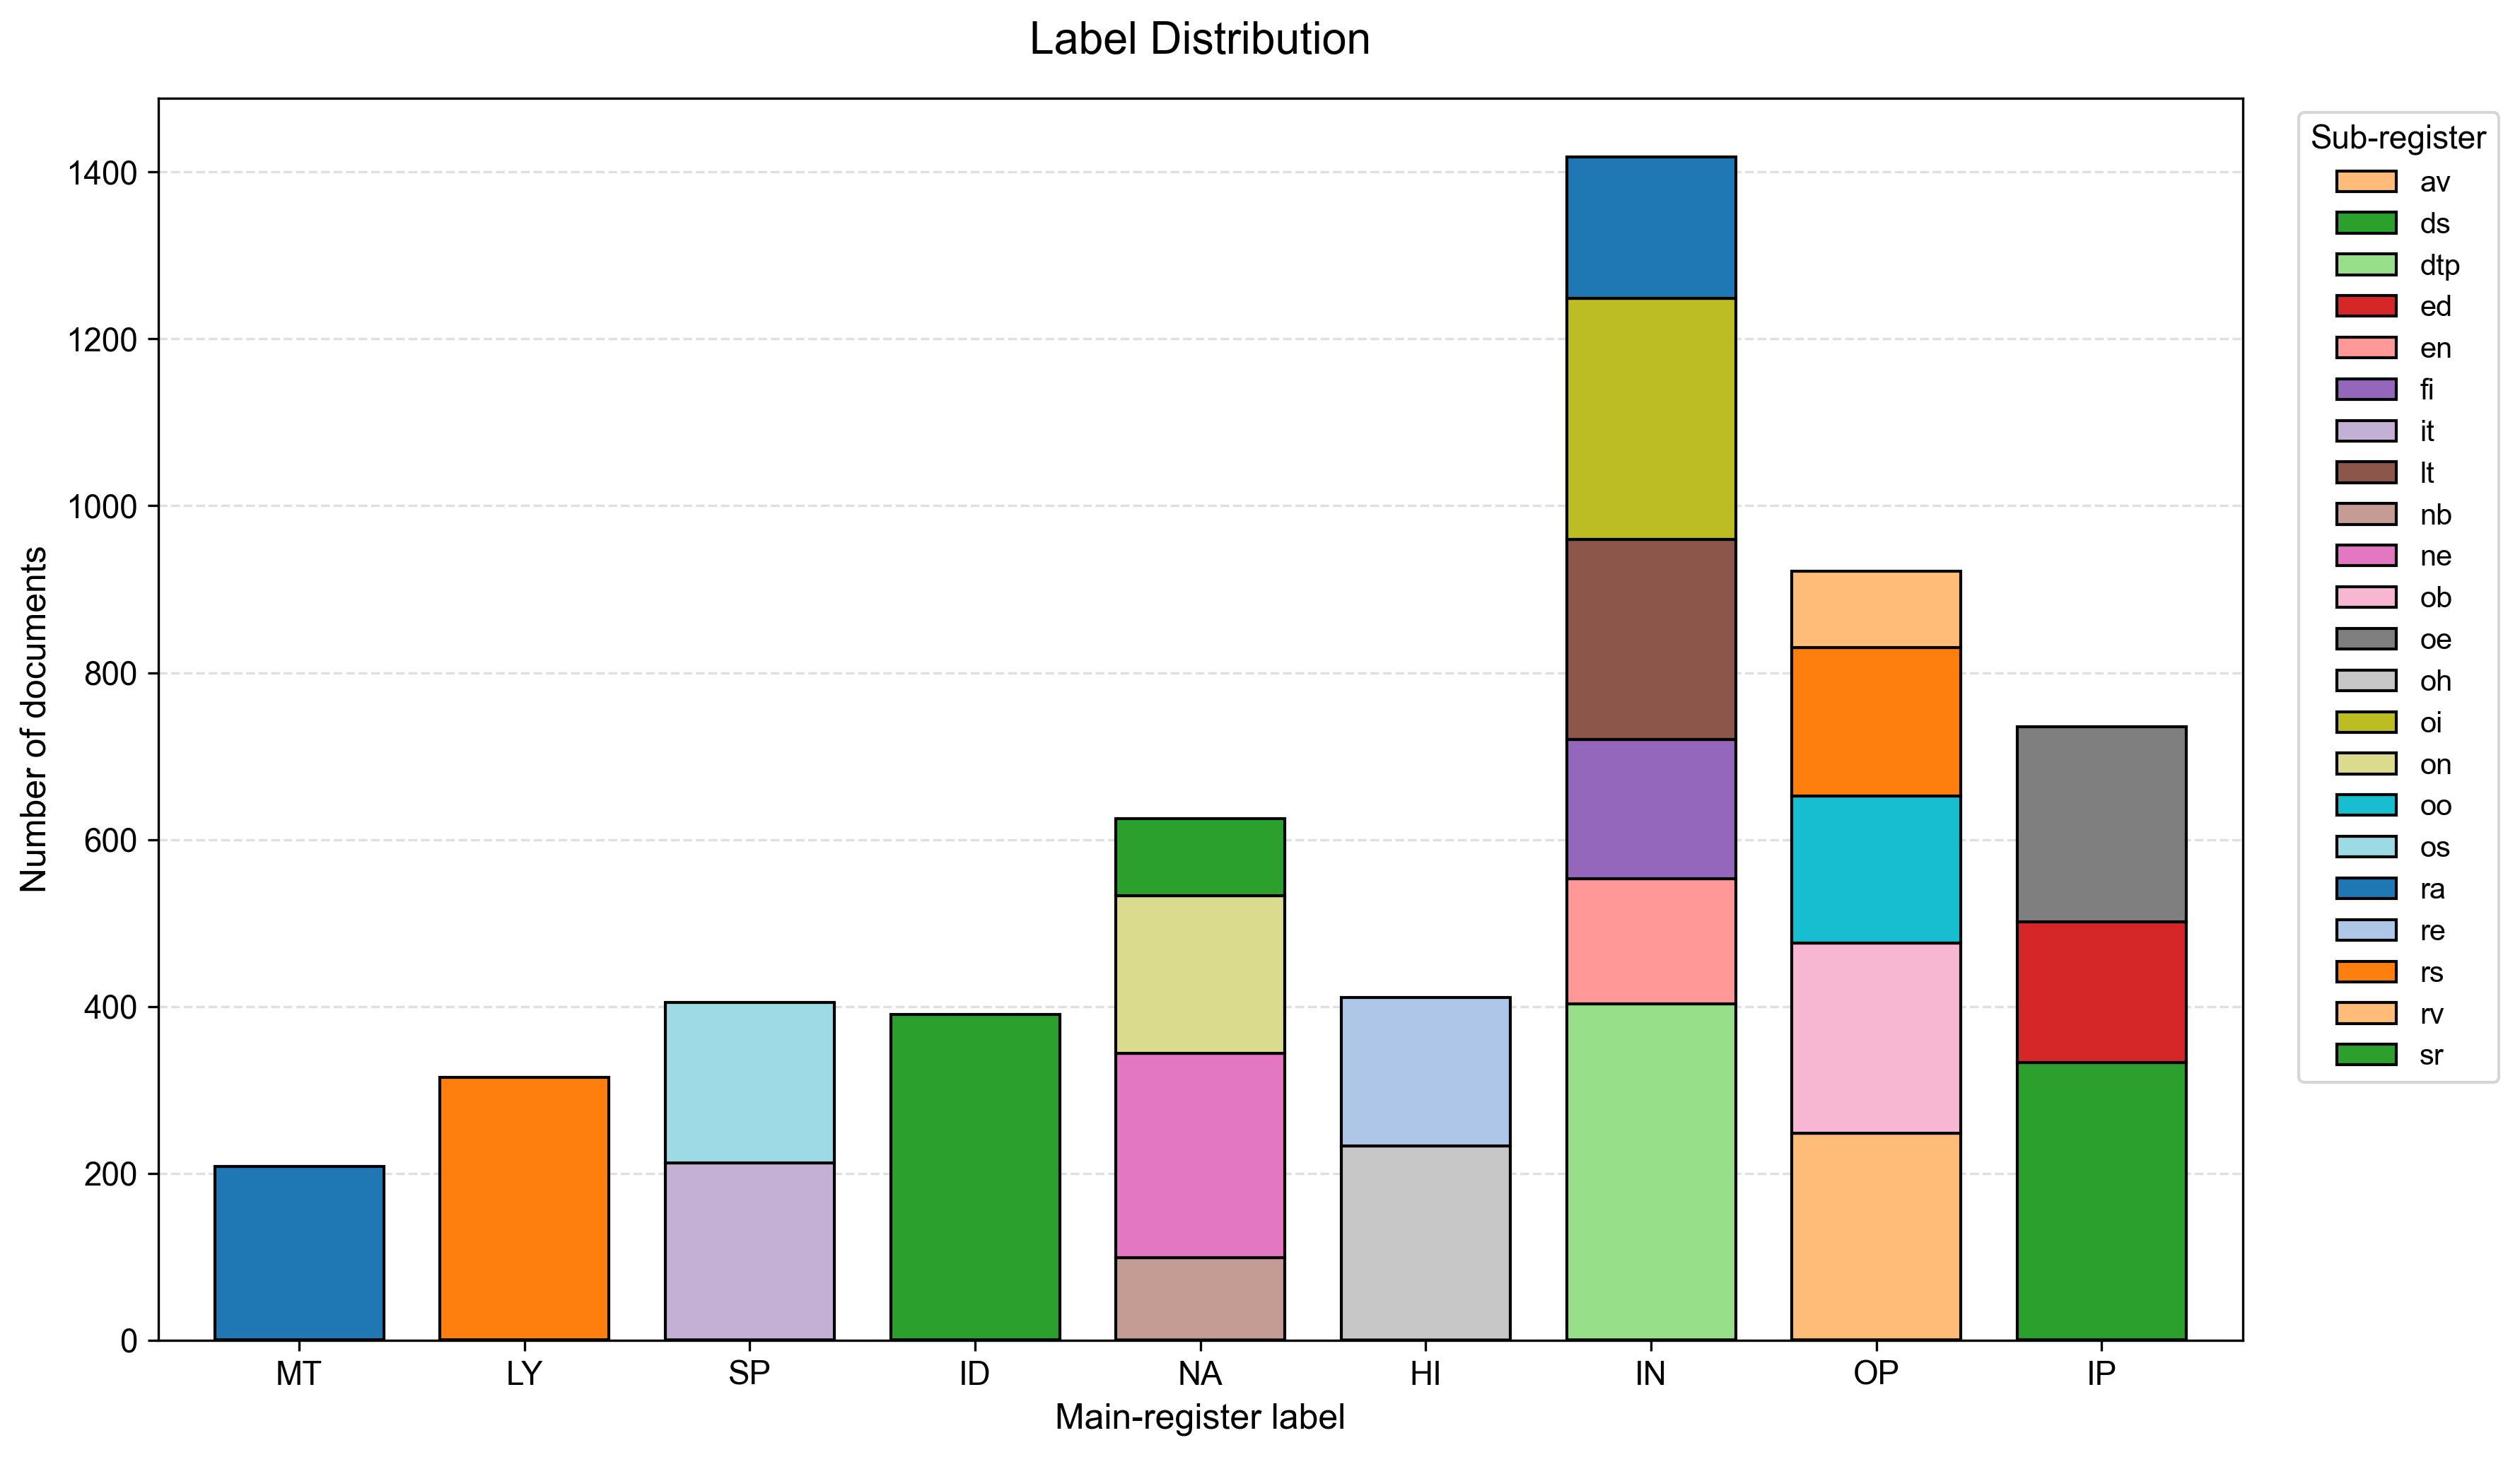

In [15]:


fig, ax = plt.subplots(figsize=FIG_SIZE)

# Generate colours for all sub-labels
cmap = plt.get_cmap("tab20")

color_dict = {
    col: cmap(i % 20)
    for i, col in enumerate(pivot_df.columns)
}

# Assign separate colours to MT, LY and ID
color_dict["MT_no_child"] = "#1f77b4"
color_dict["LY_no_child"] = "#ff7f0e"
color_dict["ID_no_child"] = "#2ca02c"


# Plot
pivot_df.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    width=0.75,
    color=[color_dict[col] for col in pivot_df.columns],
    edgecolor="black"
)


# Titles and labels
ax.set_title(
    "Label Distribution",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Main-register label")
ax.set_ylabel("Number of documents")


# Exclude MT, LY and ID from the legend
handles, legend_labels = ax.get_legend_handles_labels()

filtered = [
    (h, l)
    for h, l in zip(handles, legend_labels)
    if l not in [
        "MT_no_child",
        "LY_no_child",
        "ID_no_child"
    ]
]

ax.legend(
    [h for h, l in filtered],
    [l for h, l in filtered],
    title="Sub-register",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)


# Formatting
ax.tick_params(axis="x", rotation=0)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.set_axisbelow(True)

fig.tight_layout()


# Save
save_plot(fig, "label_distribution")

# Display
plt.show()

# Close figure after displaying
plt.close(fig)

In [14]:

os.makedirs("tables", exist_ok=True)

parent_counts.to_csv(
    "tables/parent_label_counts.csv",
    index=False
)

child_counts.to_csv(
    "tables/sub_label_counts.csv",
    index=False
)

hierarchy_counts.to_csv(
    "tables/hierarchy_counts.csv",
    index=False
)

print("All tables saved successfully!")

All tables saved successfully!


PNG saved: plots\label_distribution_with_counts.png
PDF saved: plots\label_distribution_with_counts.pdf


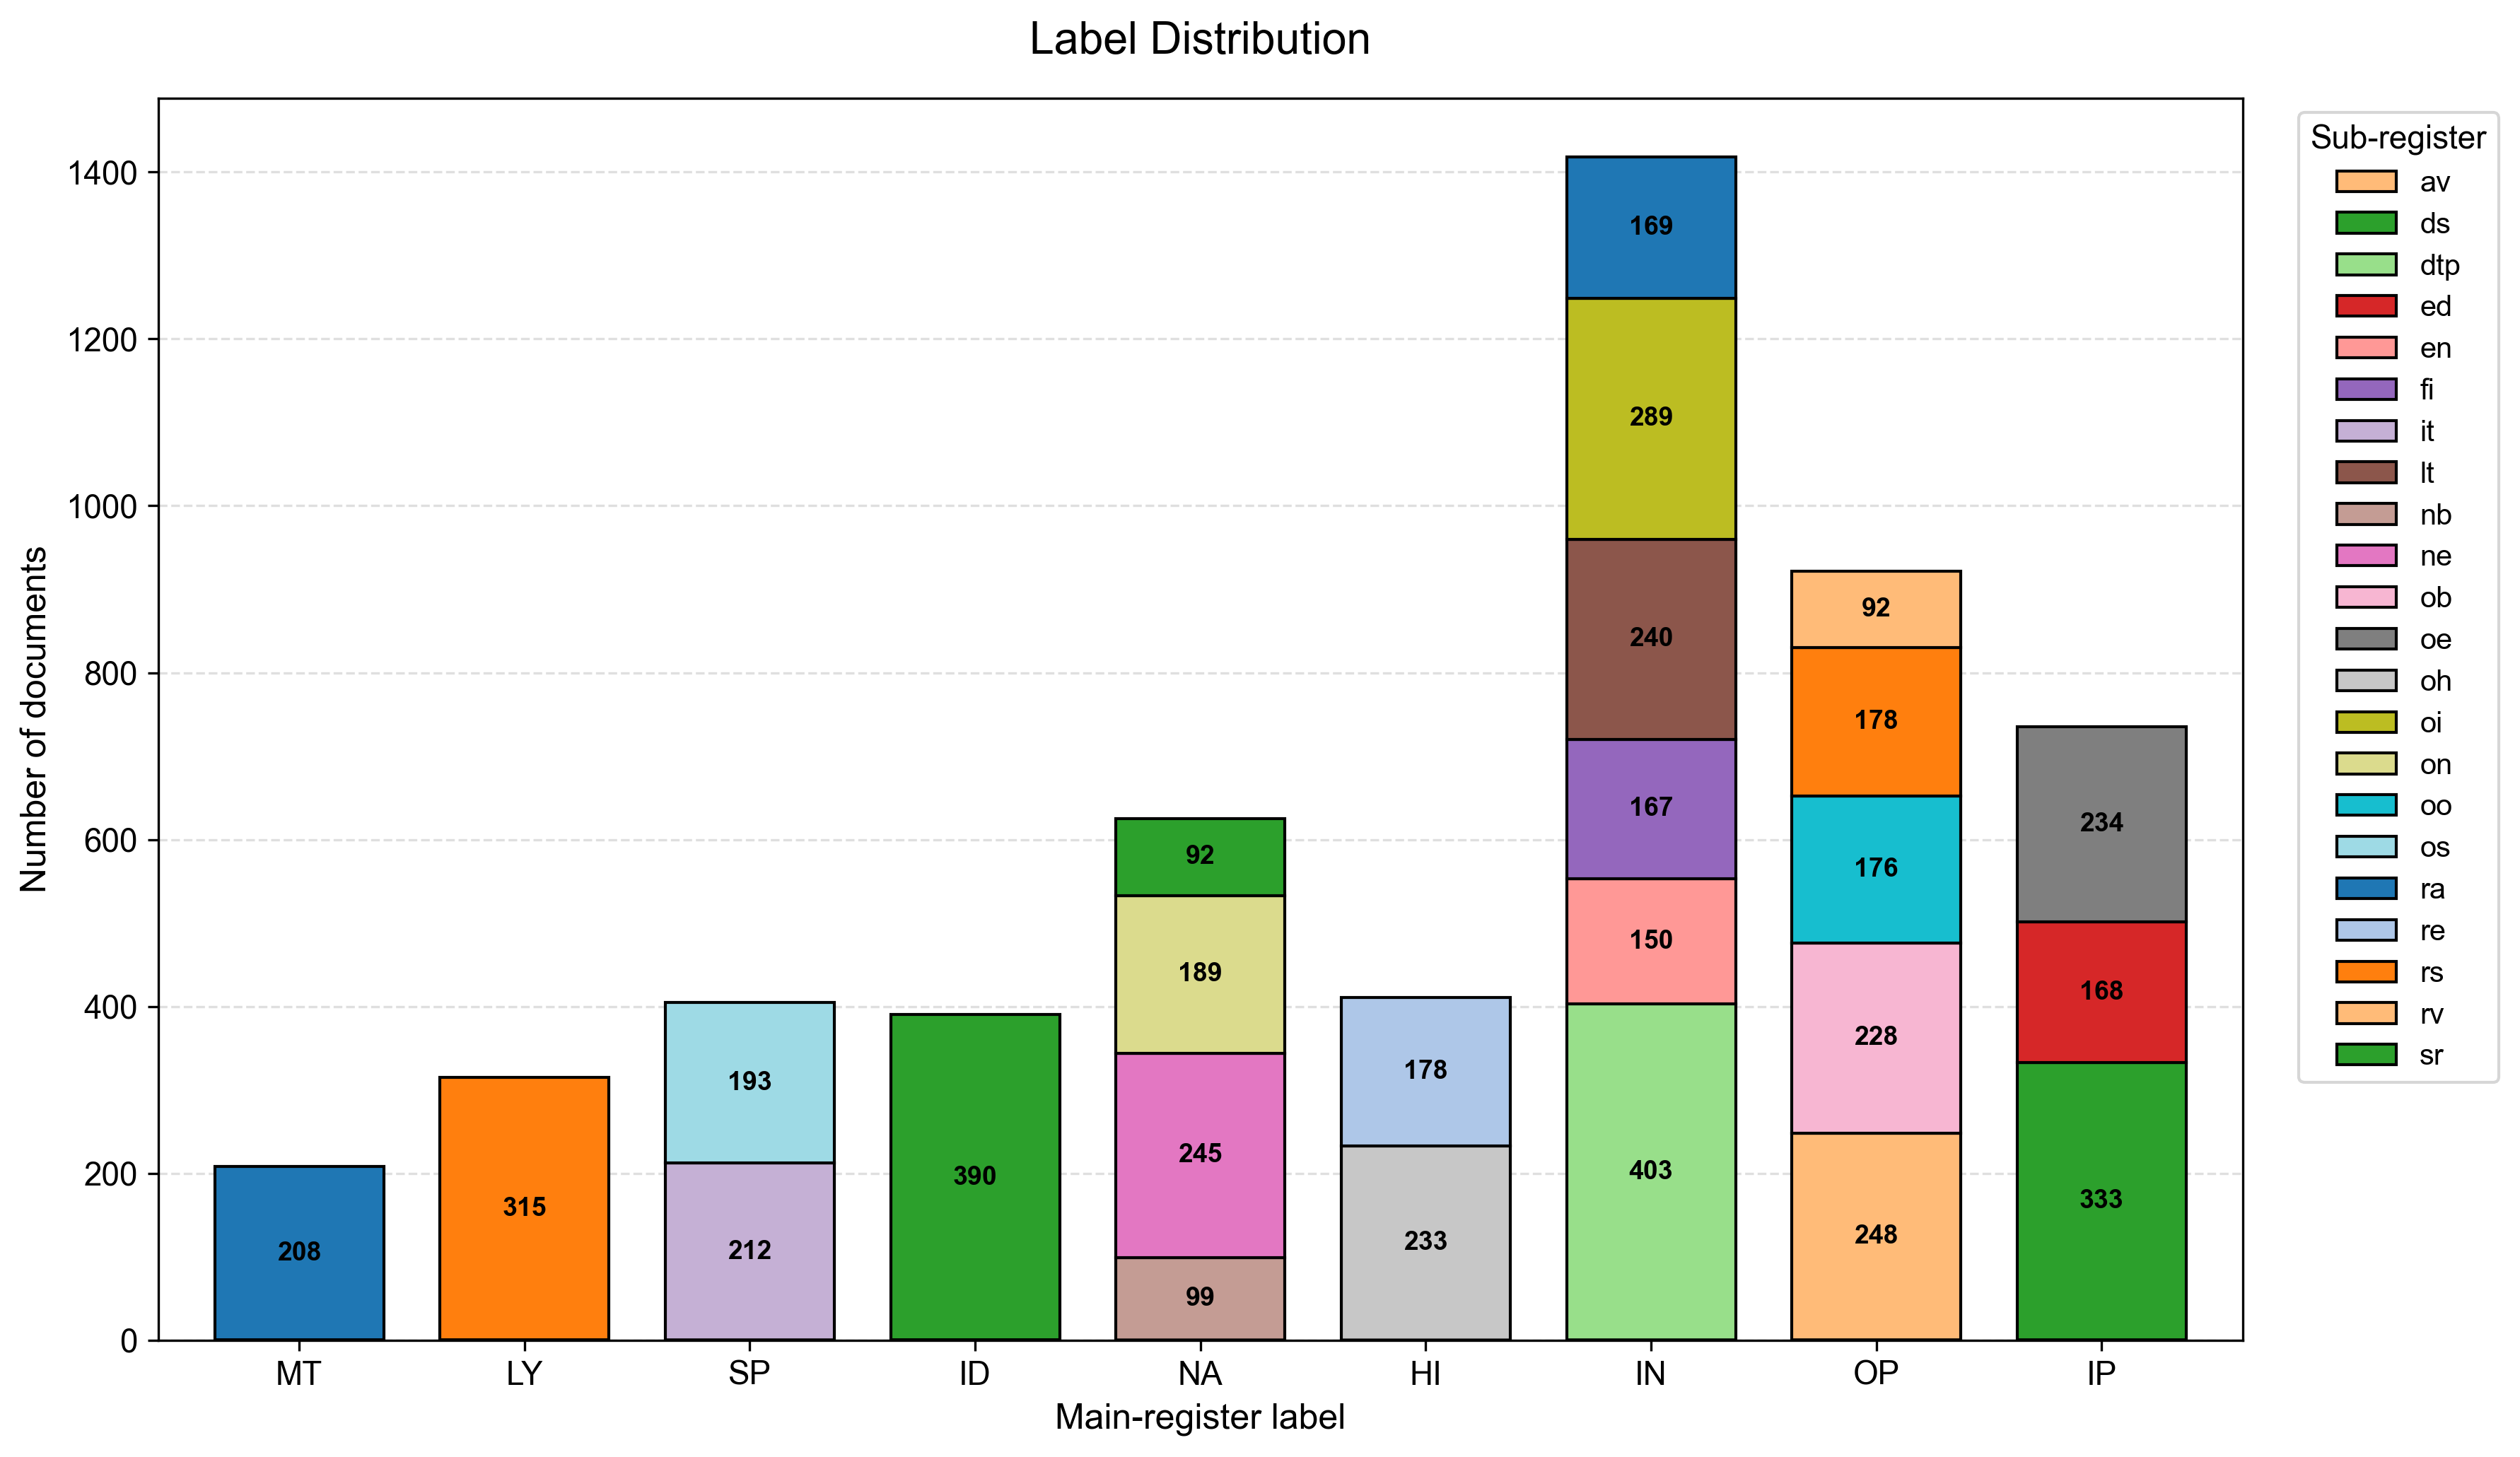

In [17]:

# ==========================================
# SECOND PLOT: WITH SUB-REGISTER COUNTS
# ==========================================

fig, ax = plt.subplots(figsize=FIG_SIZE)

# Plot
pivot_df.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    width=0.75,
    color=[color_dict[col] for col in pivot_df.columns],
    edgecolor="black"
)

# Add counts inside each bar segment
for container in ax.containers:

    labels = [
        f"{int(bar.get_height())}" if bar.get_height() > 0 else ""
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        color="black",
        fontsize=9,
        fontweight="bold"
    )

# Titles and labels
ax.set_title(
    "Label Distribution",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Main-register label")
ax.set_ylabel("Number of documents")

# Exclude MT, LY and ID from the legend
handles, legend_labels = ax.get_legend_handles_labels()

filtered = [
    (h, l)
    for h, l in zip(handles, legend_labels)
    if l not in [
        "MT_no_child",
        "LY_no_child",
        "ID_no_child"
    ]
]

ax.legend(
    [h for h, l in filtered],
    [l for h, l in filtered],
    title="Sub-register",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

# Formatting
ax.tick_params(axis="x", rotation=0)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.set_axisbelow(True)

fig.tight_layout()

# Save second plot
save_plot(fig, "label_distribution_with_counts")

# Display
plt.show()

# Close figure
plt.close(fig)


# Tags distribution

In [18]:

# ==========================================
# PROCESS TAGS
# ==========================================

tags_df = df[["id", "Tags"]].copy()

# Split multiple tags
tags_df["Tags"] = tags_df["Tags"].fillna("").astype(str)

tags_df["Tags"] = tags_df["Tags"].apply(
    lambda x: [tag.strip() for tag in x.split(";") if tag.strip()]
)

# Explode tags
tags_exploded = tags_df.explode("Tags")

# Remove empty values
tags_exploded = tags_exploded[
    tags_exploded["Tags"].notna() &
    (tags_exploded["Tags"] != "")
].copy()

# Remove duplicate document-tag combinations
tags_exploded = tags_exploded.drop_duplicates(
    subset=["id", "Tags"]
)

display(tags_exploded.head())


,id,Tags
0,110ae9e775485f536c4f1cdea087cbd7,OTHLI
4,588d3acafdc57f5122849f3163c1d357,OTHLI
5,9afaecf7d64a78e22fa71dec39be048b,OTHLI
10,2ddf12198c0e9ee279ddf868125c8b1b,OTHLI
11,d0382160b4fa37e77c8e42c43f83c77f,OTHLI


In [19]:

# ==========================================
# DOCUMENT COUNTS PER TAG
# ==========================================

tag_counts = (
    tags_exploded
    .groupby("Tags")["id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index()
)

tag_counts.columns = [
    "Tag",
    "Number of documents"
]

print("DOCUMENT COUNTS PER TAG")

display(tag_counts)


DOCUMENT COUNTS PER TAG


,Tag,Number of documents
0,OTHLI,1628
1,LINK,92
2,FINGLISH,21
3,UNC,9
4,OTHL,8
5,DIAL,1
6,JNK,1
7,MLPT,1
8,hnd,1


PNG saved: plots\tag_distribution.png
PDF saved: plots\tag_distribution.pdf


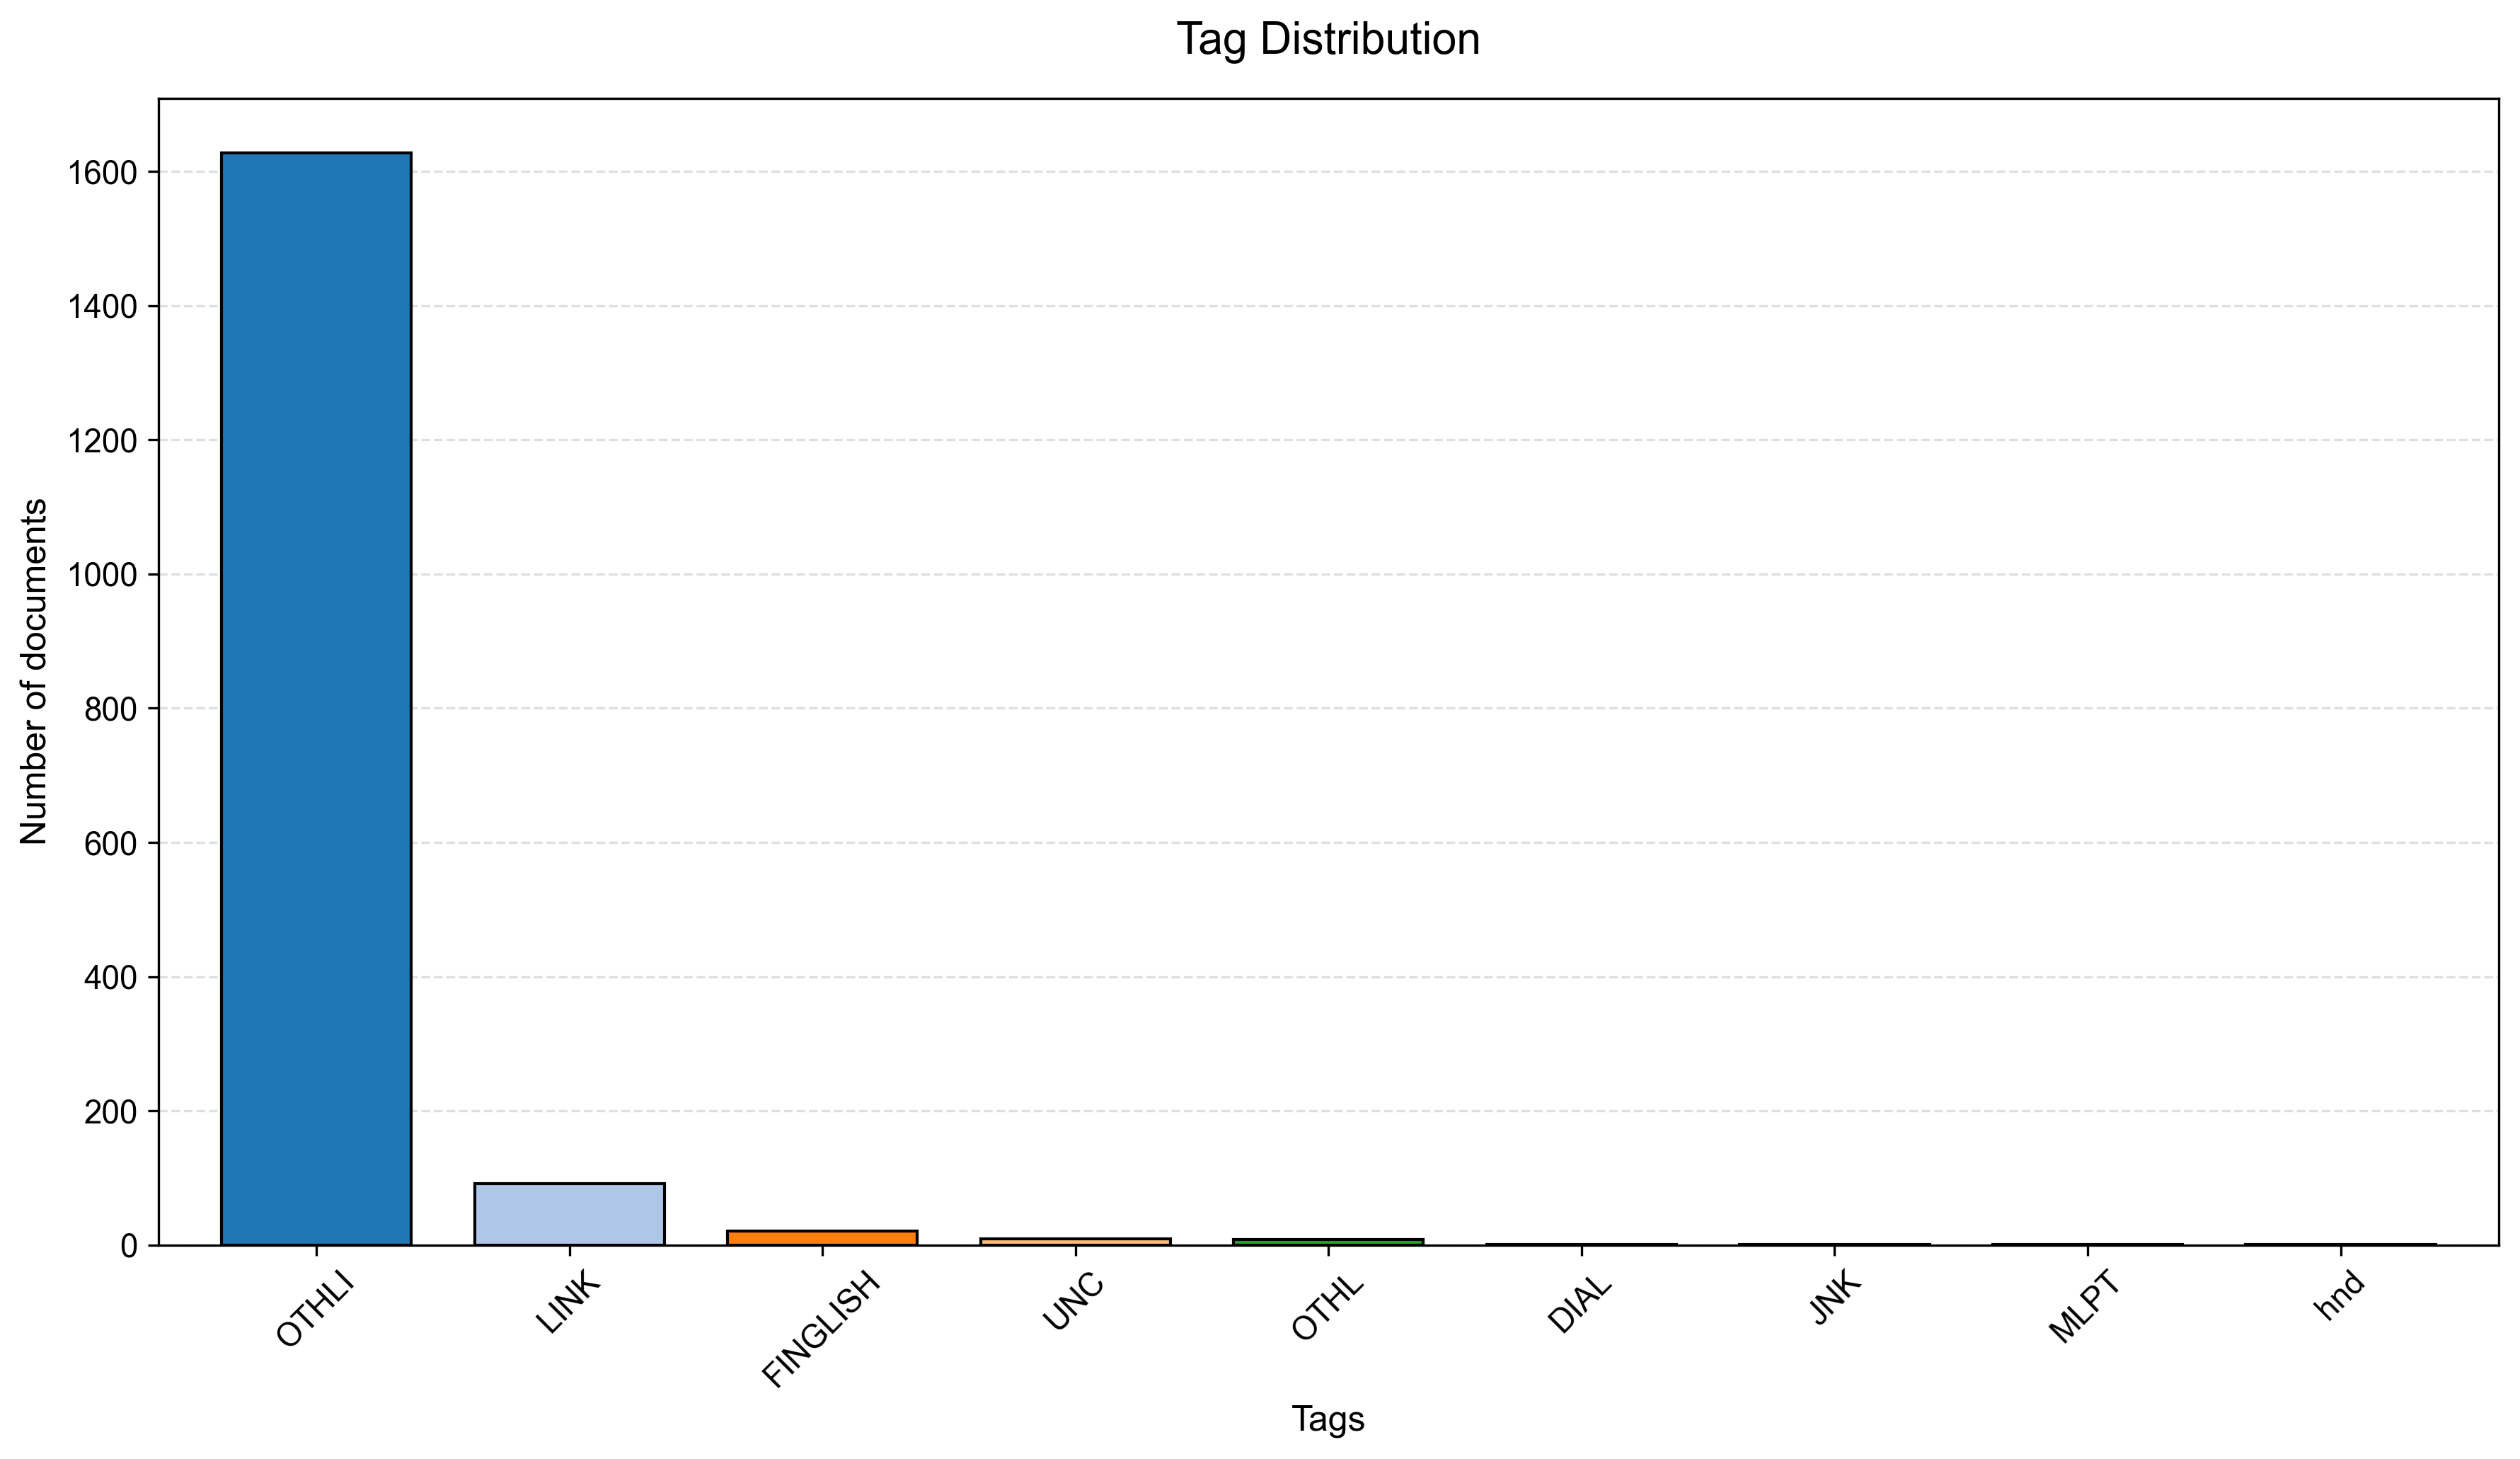

In [20]:

# ==========================================
# TAG DISTRIBUTION
# ==========================================

fig, ax = plt.subplots(figsize=FIG_SIZE)

# Plot
tag_counts.plot(
    kind="bar",
    x="Tag",
    y="Number of documents",
    ax=ax,
    width=0.75,
    color=plt.get_cmap("tab20").colors,
    edgecolor="black",
    legend=False
)

ax.set_title(
    "Tag Distribution",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Tags")
ax.set_ylabel("Number of documents")

ax.tick_params(axis="x", rotation=45)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.set_axisbelow(True)

fig.tight_layout()

save_plot(fig, "tag_distribution")

plt.show()
plt.close(fig)


In [21]:

# ==========================================
# TAG DISTRIBUTION WITHIN MAIN REGISTERS
# ==========================================

selected_tags = ["OTHLI", "LINK", "FINGLISH"]

# Prepare document-tag data
tags_df = df[["id", "Tags"]].copy()

tags_df["Tags"] = tags_df["Tags"].fillna("").astype(str)

tags_df["Tags"] = tags_df["Tags"].apply(
    lambda x: list(set(
        tag.strip()
        for tag in x.split(";")
        if tag.strip()
    ))
)

# Identify documents with no tags
no_tag_documents = set(
    tags_df.loc[
        tags_df["Tags"].apply(len) == 0,
        "id"
    ]
)

# Explode tags
tags_exploded = tags_df.explode("Tags")

# Keep only the selected tags
tags_exploded = tags_exploded[
    tags_exploded["Tags"].isin(selected_tags)
].copy()

# Remove duplicate document-tag combinations
tags_exploded = tags_exploded.drop_duplicates(
    subset=["id", "Tags"]
)

# Add documents without tags
no_tag_df = pd.DataFrame({
    "id": list(no_tag_documents),
    "Tags": "No tag"
})

tags_exploded = pd.concat(
    [tags_exploded, no_tag_df],
    ignore_index=True
)

# ==========================================
# CONNECT TAGS TO MAIN REGISTERS
# ==========================================

# Get document-parent combinations
register_documents = valid_hierarchy[
    ["id", "parent"]
].drop_duplicates()

# Merge tags with main registers
register_tags = register_documents.merge(
    tags_exploded,
    on="id",
    how="left"
)

# Documents without any selected tag should not be
# confused with documents having other, unselected tags.
# Add No tag only for genuinely empty Tags cells.

register_tags["Tags"] = register_tags["Tags"].fillna(
    "Other / unselected"
)

# Keep only selected tags and No tag
register_tags = register_tags[
    register_tags["Tags"].isin(
        selected_tags + ["No tag"]
    )
].copy()

# ==========================================
# COUNT DOCUMENTS
# ==========================================

# Total documents per main register
register_totals = (
    register_documents
    .groupby("parent")["id"]
    .nunique()
    .reindex(labels_structure.keys(), fill_value=0)
)

# Counts per register and tag
register_tag_counts = (
    register_tags
    .groupby(["parent", "Tags"])["id"]
    .nunique()
    .unstack(fill_value=0)
)

# Ensure all categories are present
categories = selected_tags + ["No tag"]

register_tag_counts = register_tag_counts.reindex(
    index=register_totals.index,
    columns=categories,
    fill_value=0
)

# Calculate percentages
register_tag_percentages = (
    register_tag_counts
    .div(register_totals.replace(0, float("nan")), axis=0)
    * 100
).fillna(0)

print("DOCUMENT COUNTS")
display(register_tag_counts)

print("PERCENTAGES PER MAIN REGISTER")
display(register_tag_percentages.round(2))


DOCUMENT COUNTS


Tags,OTHLI,LINK,FINGLISH,No tag
parent,,,,
MT,183,2,0,23
LY,104,1,1,205
SP,92,11,0,302
ID,179,12,19,184
NA,185,18,3,418
HI,200,22,4,188
IN,615,31,10,757
OP,282,32,5,596
IP,410,12,5,309


PERCENTAGES PER MAIN REGISTER


Tags,OTHLI,LINK,FINGLISH,No tag
parent,,,,
MT,87.98,0.96,0.00,11.06
LY,33.02,0.32,0.32,65.08
SP,22.72,2.72,0.00,74.57
ID,45.90,3.08,4.87,47.18
NA,29.60,2.88,0.48,66.88
HI,48.66,5.35,0.97,45.74
IN,43.37,2.19,0.71,53.39
OP,30.59,3.47,0.54,64.64
IP,55.78,1.63,0.68,42.04


PNG saved: plots\tag_distribution_by_main_register.png
PDF saved: plots\tag_distribution_by_main_register.pdf


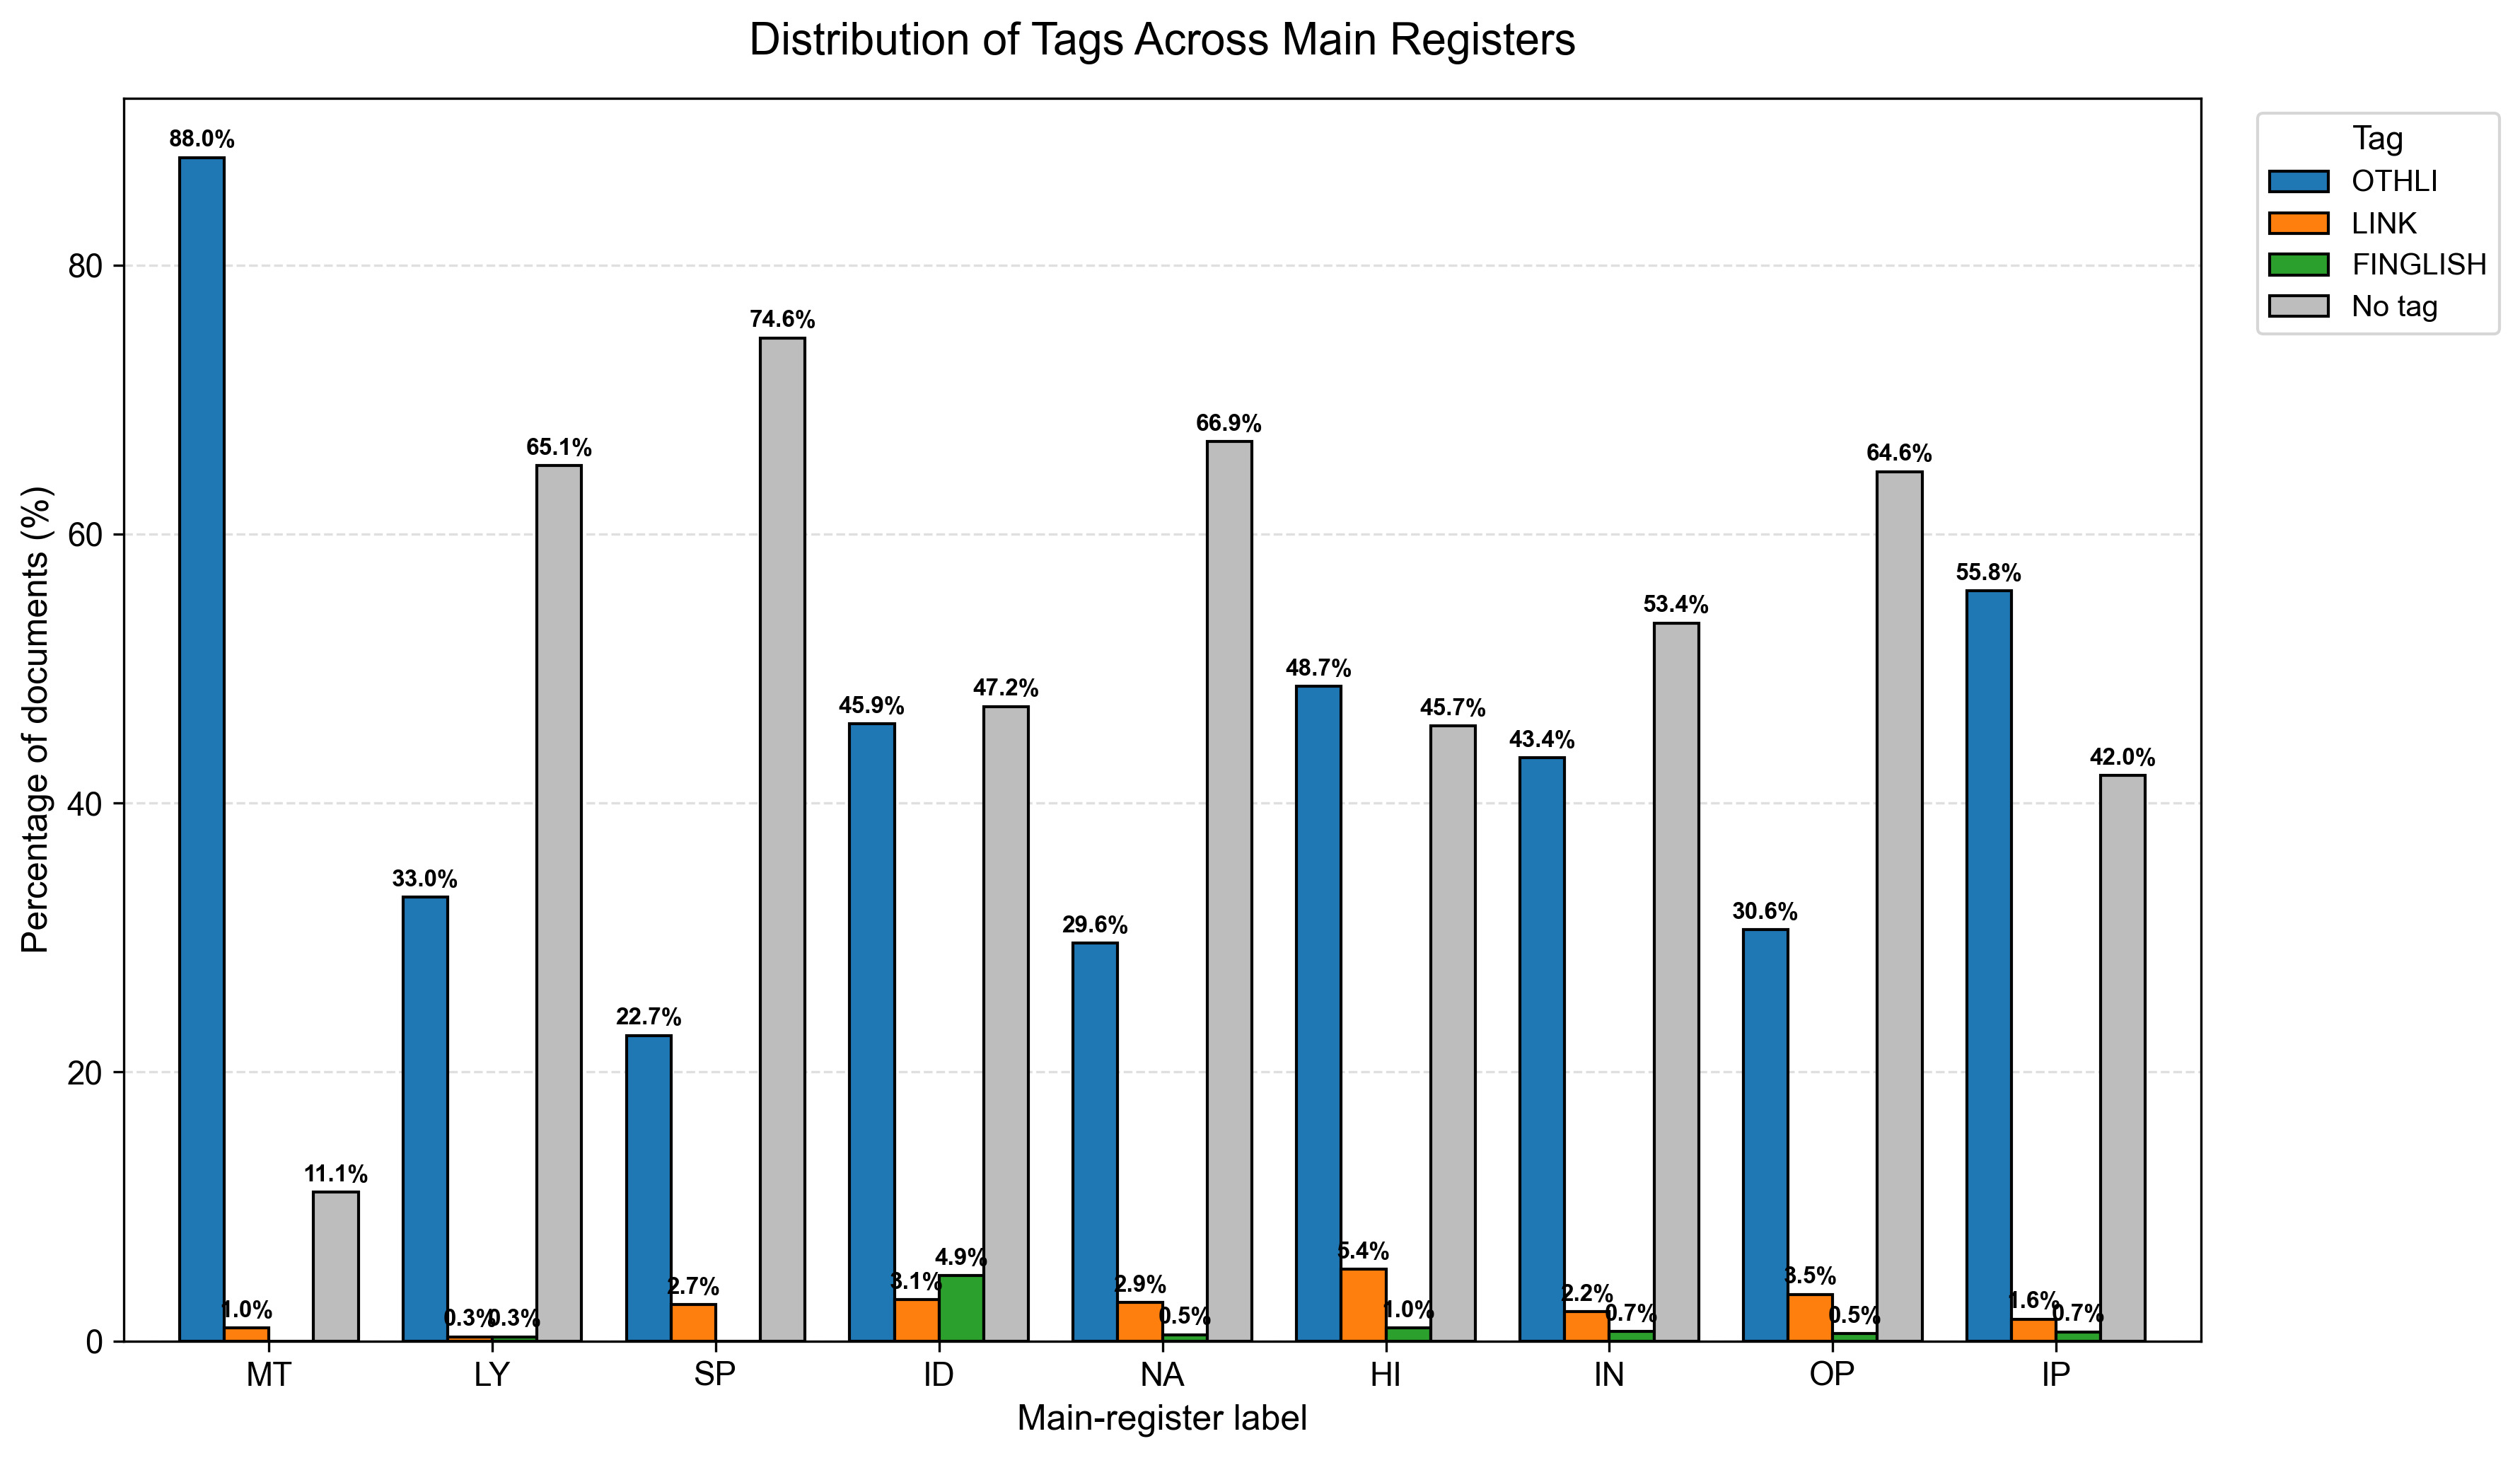

In [23]:

# ==========================================
# PLOT TAG PROPORTIONS PER MAIN REGISTER
# ==========================================

fig, ax = plt.subplots(figsize=FIG_SIZE)

colors = {
    "OTHLI": "#1f77b4",
    "LINK": "#ff7f0e",
    "FINGLISH": "#2ca02c",
    "No tag": "#bdbdbd"
}

register_tag_percentages.plot(
    kind="bar",
    ax=ax,
    width=0.8,
    color=[colors[col] for col in categories],
    edgecolor="black"
)

# Add percentage labels
for container in ax.containers:

    labels = [
        f"{bar.get_height():.1f}%"
        if bar.get_height() > 0 else ""
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        fontsize=8,
        color="black",
        fontweight="bold",
        padding=2
    )

ax.set_title(
    "Distribution of Tags Across Main Registers",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Main-register label")
ax.set_ylabel("Percentage of documents (%)")

ax.legend(
    title="Tag",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.tick_params(axis="x", rotation=0)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.set_axisbelow(True)

fig.tight_layout()

save_plot(fig, "tag_distribution_by_main_register")

plt.show()
plt.close(fig)


In [24]:
register_tag_counts.to_csv(
    "tables/tag_counts_by_main_register.csv"
)

register_tag_percentages.to_csv(
    "tables/tag_percentages_by_main_register.csv"
)